# Bài 1. Tìm kiếm cục bộ trên mê cung – Simple Hill Climbing
**Yêu cầu:** đọc `L_maze.txt`, hiển thị bằng `maze_helper`, quan sát N/E/S/W + `expand`, phân tích `manhattan` + `local_search`, chạy animation, ghi nhận `result["solution"]` so với G, giải thích kẹt cực tiểu địa phương, thử đổi `ORDER/RANDOMIZATION`.

Heuristic: $h(n) = |r_n - r_G| + |c_n - c_G|$ (giảm h là cải thiện).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
# tim maze_helper o nhieu vi tri
for p in [os.getcwd(), r"D:\LAB03\lab03 - local search\lab03 - local search",
          "lab03 - local search/lab03 - local search"]:
    if p not in sys.path:
        sys.path.insert(0, p)
import maze_helper as mh
print("maze_helper OK")


maze_helper OK


Doc maze tu: D:\LAB03\lab03 - local search\lab03 - local search\L_maze.txt
[['X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'G' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' 'X' 'X' 'X' 'X' 'X' 'X' 'X' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' 'S' ' ' ' ' ' ' ' ' 'X' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X']
 ['X' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' ' 'X']
 ['X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' 'X' '

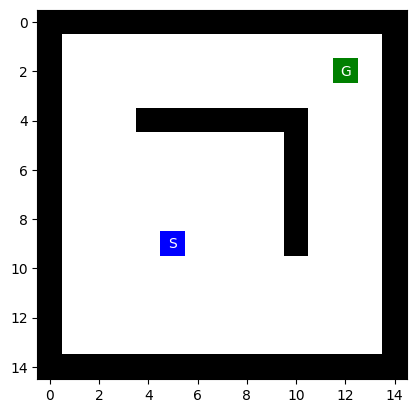

In [2]:
# 1) Doc L_maze.txt va hien thi ban do
import os
cands = ["L_maze.txt",
         r"D:\LAB03\lab03 - local search\lab03 - local search\L_maze.txt",
         "lab03 - local search/lab03 - local search/L_maze.txt"]
maze_path = next((p for p in cands if os.path.exists(p)), None)
print("Doc maze tu:", maze_path)
maze = mh.parse_maze(open(maze_path, encoding="utf-8").read())
print(maze)
start_pos = mh.find_pos(maze, "S")
goal_pos = mh.find_pos(maze, "G")
print(f"Start S = {tuple(map(int, start_pos))}, Goal G = {tuple(map(int, goal_pos))}")
mh.show_maze(maze)


## 2. Các hướng N/E/S/W và hàm `expand`
`expand(maze, pos)` liệt kê các ô kề không phải tường `'X'`. `ORDER` quyết định thứ tự xét, `RANDOMIZATION=True` thì xáo trộn mỗi bước.

In [3]:
DIR2POS = {'N': (-1, 0), 'E': (0, 1), 'S': (1, 0), 'W': (0, -1)}
ORDER = None; RANDOMIZATION = None; DIRS = None

def set_order(order="NESW", random=False, verbose=True):
    global RANDOMIZATION, ORDER, DIRS
    RANDOMIZATION = random
    ORDER = [c for c in order]
    DIRS = [DIR2POS[d] for d in ORDER]
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")

set_order("NESW", verbose=True)

def expand(maze, pos):
    """Sinh lân cận hợp lệ: các ô không phải tường 'X'."""
    global RANDOMIZATION, DIRS, ORDER
    available = [[d, p] for d, p in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, p) != "X"]
    if RANDOMIZATION:
        np.random.shuffle(available)
    return available

print("Lan can cua S:", [(d, tuple(map(int, p))) for d, p in expand(maze, start_pos)])


Directions are checked in the order ['N', 'E', 'S', 'W']
Lan can cua S: [('N', (8, 5)), ('E', (9, 6)), ('S', (10, 5)), ('W', (9, 4))]


## 3. Hàm `manhattan` và `local_search`
`manhattan` là khoảng cách Manhattan tới G (bỏ qua tường). `local_search` mỗi bước chọn lân cận có `h` nhỏ nhất, chỉ di chuyển nếu `best < hiện tại`, ngược lại dừng (leo đồi đơn, tham lam).

In [4]:
def manhattan(pos1, pos2):
    """h(n) = |r_n-r_G| + |c_n-c_G|."""
    return np.sum(np.abs(np.subtract(pos1, pos2)))

print(manhattan([0, 0], [1, 1]))  # kiem tra mau = 2
print(f"h(S,G) = {int(manhattan(start_pos, goal_pos))}")

def local_search(maze, vis=False, animation=False, verbose=False):
    maze_anim = [] if animation else None
    current = mh.find_pos(maze, "S")
    goal = mh.find_pos(maze, "G")
    current_obj = manhattan(current, goal)
    steps = [(tuple(map(int, current)), int(current_obj))]
    while True:
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]
        if verbose:
            print("Current state:", tuple(map(int, current)), "with obj", int(current_obj))
            print("Evaluating neighbors:\t", [tuple(map(int, n)) for n in neighbors])
            print("Obj:\t\t\t", [int(o) for o in obj])
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            steps.append((tuple(map(int, np.asarray(current).flatten())), int(current_obj)))
            if verbose:
                print("Moving to:", tuple(map(int, np.asarray(current).flatten())), "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break
        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)
    reached = (tuple(map(int, np.asarray(current).flatten())) == tuple(map(int, np.asarray(goal).flatten())))
    return {"solution": current, "path": None, "reached": reached,
            "maze_anim": maze_anim, "steps": steps, "h": int(current_obj), "goal": goal}


2
h(S,G) = 14


In [5]:
# 4) Chay chinh + animation
set_order("NESW", random=False, verbose=True)
%time result = local_search(maze, animation=True, verbose=True)
sol = tuple(map(int, np.asarray(result['solution']).flatten()))
goal = tuple(map(int, np.asarray(result['goal']).flatten()))
print(f"result['solution'] = {sol}, h = {result['h']}")
print(f"Dich G = {goal}, h(G,G) = 0, toi dich? {result['reached']}")
mh.animate_maze(result)


Directions are checked in the order ['N', 'E', 'S', 'W']
Current state: (9, 5) with obj 14
Evaluating neighbors:	 [(8, 5), (9, 6), (10, 5), (9, 4)]
Obj:			 [13, 13, 15, 15]
Moving to: (8, 5) 

Current state: (8, 5) with obj 13
Evaluating neighbors:	 [(7, 5), (8, 6), (9, 5), (8, 4)]
Obj:			 [12, 12, 14, 14]
Moving to: (7, 5) 

Current state: (7, 5) with obj 12
Evaluating neighbors:	 [(6, 5), (7, 6), (8, 5), (7, 4)]
Obj:			 [11, 11, 13, 13]
Moving to: (6, 5) 

Current state: (6, 5) with obj 11
Evaluating neighbors:	 [(5, 5), (6, 6), (7, 5), (6, 4)]
Obj:			 [10, 10, 12, 12]
Moving to: (5, 5) 

Current state: (5, 5) with obj 10
Evaluating neighbors:	 [(5, 6), (6, 5), (5, 4)]
Obj:			 [9, 11, 11]
Moving to: (5, 6) 

Current state: (5, 6) with obj 9
Evaluating neighbors:	 [(5, 7), (6, 6), (5, 5)]
Obj:			 [8, 10, 10]
Moving to: (5, 7) 

Current state: (5, 7) with obj 8
Evaluating neighbors:	 [(5, 8), (6, 7), (5, 6)]
Obj:			 [7, 9, 9]
Moving to: (5, 8) 

Current state: (5, 8) with obj 7
Evaluat

In [ ]:
# Ve them anh duong di Hill Climbing (tao file hill_climbing_path_NESW.png)
maze_path = maze.copy()
for (r, c), _ in result["steps"]:
    if maze_path[r, c] not in ("S", "G"):
        maze_path[r, c] = "P"
fig, ax = plt.subplots()
ax.imshow(mh.maze_to_matrix(maze_path))
ax.set_title(f"Hill Climbing NESW: dung tai {sol} h={result['h']} (G={goal})")
plt.savefig("hill_climbing_path_NESW.png", dpi=150, bbox_inches="tight")
plt.show()
print("Da luu: hill_climbing_path_NESW.png")


## 5. Kết quả & giải thích
Với `NESW`: `(9,5)→(8,5)→(7,5)→(6,5)→(5,5)→(5,6)→(5,7)→(5,8)→(5,9)` rồi **DỪNG**.
`result["solution"]=(5,9), h=6` trong khi `G=(2,12), h=0` → **chưa đến đích**.
Lý do: tại `(5,9)` lân cận chỉ có `(6,9)h=7, (5,8)h=7` đều tệ hơn nên `best<hiện tại` sai → `break`. Đây là **cực tiểu địa phương**: `h` Manhattan bỏ qua tường nên bị hút vào góc `(5,9)` gần đích theo đường chim bay nhưng bị tường chặn.

In [6]:
# 6) Thu doi ORDER
for order in ["NESW", "ESWN", "SENW", "WSEN", "NSEW"]:
    set_order(order, random=False, verbose=False)
    r = local_search(maze, verbose=False)
    s = tuple(map(int, np.asarray(r['solution']).flatten()))
    print(f"ORDER={order}: dung tai {s} h={r['h']} | toi G? {r['reached']} | buoc={len(r['steps'])} | {[p for p,_ in r['steps']]}")


ORDER=NESW: dung tai (5, 9) h=6 | toi G? False | buoc=9 | [(9, 5), (8, 5), (7, 5), (6, 5), (5, 5), (5, 6), (5, 7), (5, 8), (5, 9)]
ORDER=ESWN: dung tai (5, 9) h=6 | toi G? False | buoc=9 | [(9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (8, 9), (7, 9), (6, 9), (5, 9)]
ORDER=SENW: dung tai (5, 9) h=6 | toi G? False | buoc=9 | [(9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (8, 9), (7, 9), (6, 9), (5, 9)]
ORDER=WSEN: dung tai (5, 9) h=6 | toi G? False | buoc=9 | [(9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (8, 9), (7, 9), (6, 9), (5, 9)]
ORDER=NSEW: dung tai (5, 9) h=6 | toi G? False | buoc=9 | [(9, 5), (8, 5), (7, 5), (6, 5), (5, 5), (5, 6), (5, 7), (5, 8), (5, 9)]


In [7]:
# 7) Thu RANDOMIZATION=True, chay 5 lan
set_order("NESW", random=True, verbose=False)
for trial in range(5):
    np.random.seed(trial)
    r = local_search(maze, verbose=False)
    s = tuple(map(int, np.asarray(r['solution']).flatten()))
    print(f"Lan {trial}: dung tai {s} h={r['h']} | toi G? {r['reached']}")
print("Nhan xet: doi ORDER chi doi tie-break luc hoa h (VD (9,5): N/E cung h=13), "
      "2 ho duong khac nhau nhung cung hoi tu (5,9); random 5/5 lan van ket -> han che co huu, "
      "can restart/SA/A* moi thoat.")


Lan 0: dung tai (5, 9) h=6 | toi G? False
Lan 1: dung tai (5, 9) h=6 | toi G? False
Lan 2: dung tai (5, 9) h=6 | toi G? False
Lan 3: dung tai (5, 9) h=6 | toi G? False
Lan 4: dung tai (5, 9) h=6 | toi G? False
Nhan xet: doi ORDER chi doi tie-break luc hoa h (VD (9,5): N/E cung h=13), 2 ho duong khac nhau nhung cung hoi tu (5,9); random 5/5 lan van ket -> han che co huu, can restart/SA/A* moi thoat.
